In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [12]:
solar_system_data = pd.read_csv("../../course_assignments/homework9/solar_system.csv", index_col=0)

In [5]:
print(f'Shape of dataset: {solar_system_data.shape}')
print(f'# of rows: {solar_system_data.shape[0]}, # of columns: {solar_system_data.shape[1]}')
display(solar_system_data.head()) #First 5 rows
display(solar_system_data.tail()) #Last 5 rows
print(f'Column names: {list(solar_system_data.columns)}')
print(f'Row names: {list(solar_system_data.index.tolist())}')

Shape of dataset: (20, 11)
# of rows: 20, # of columns: 11


,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
0,Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
1,Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
2,Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
3,Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
4,Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3


,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
15,Mean Temperature (C),167,464,15,-20,-65,-110,-140,-195,-200,-225
16,Surface Pressure (bars),0,92,1,0,0.01,Unknown,Unknown,Unknown,Unknown,0.00001
17,Number of Moons,0,0,1,0,2,95,274,28,16,5
18,Ring System?,No,No,No,No,No,Yes,Yes,Yes,Yes,No
19,Global Magnetic Field?,Yes,No,Yes,No,No,Yes,Yes,Yes,Yes,Unknown


Column names: ['Attribute', 'Mercury', 'Venus', 'Earth', 'Moon', 'Mars', 'Jupiter', 'Saturn', 'Uranus', 'Neptune', 'Pluto']
Row names: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


In [13]:
# Check the row order first
for i, name in enumerate(solar_system_data.index):
    print(f"Row {i}: {name}")

Row 0: Mass (10^24kg)
Row 1: Diameter (km)
Row 2: Density (kg/m^3)
Row 3: Gravity (m/s^2)
Row 4: Escape Velocity (km/s)
Row 5: Rotation Period (hours)
Row 6: Length of Day (hours)
Row 7: Distance from Sun (10^6 km)
Row 8: Perihelion (10^6 km)
Row 9: Aphelion (10^6 km)
Row 10: Orbital Period (days)
Row 11: Orbital Velocity (km/s)
Row 12: Orbital Inclination (deg)
Row 13: Orbital Eccentricity
Row 14: Obliquity to Orbit (deg)
Row 15: Mean Temperature (C)
Row 16: Surface Pressure (bars)
Row 17: Number of Moons
Row 18: Ring System?
Row 19: Global Magnetic Field?


In [15]:
orbital_period = solar_system_data.iloc[0].astype(float)
perihelion = solar_system_data.iloc[1].astype(float)
aphelion = solar_system_data.iloc[2].astype(float)

In [16]:
# 3.6
#Perihelion: the point in a planet's elliptical orbit where it is closest to Sun.
#Aphelion: the point in a planet's elliptical orbit where it is farthest from the Sun.
#Semi-major axis: half the length of the longest diameter of an elliptical orbit.

In [17]:
semi_major_axis = (perihelion + aphelion) / 2

sma_series = pd.Series(semi_major_axis, name="Semi-major axis (AU)")
solar_system_data = pd.concat([solar_system_data, sma_series.to_frame().T])

print("New shape:", solar_system_data.shape)
print(f"Rows: {solar_system_data.shape[0]}, Columns: {solar_system_data.shape[1]}")
display(solar_system_data)

New shape: (21, 10)
Rows: 21, Columns: 10


,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3
Rotation Period (hours),1407.6,-5832.5,23.9,655.7,24.6,9.9,10.7,-17.2,16.1,-153.3
Length of Day (hours),4222.6,2802.0,24.0,708.7,24.7,9.9,10.7,17.2,16.1,153.3
Distance from Sun (10^6 km),57.9,108.2,149.6,0.384,228.0,778.5,1432.0,2867.0,4515.0,5906.4
Perihelion (10^6 km),46.0,107.5,147.1,0.363,206.7,740.6,1357.6,2732.7,4471.1,4436.8
Aphelion (10^6 km),69.8,108.9,152.1,0.406,249.3,816.4,1506.5,3001.4,4558.9,7375.9


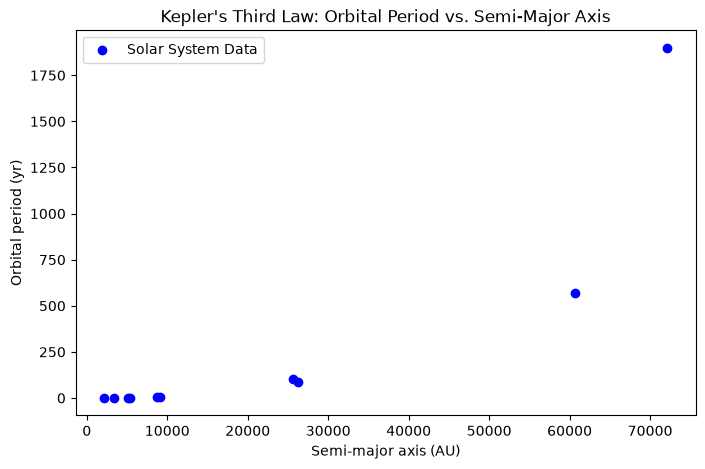

In [18]:
plt.figure(figsize=(8, 5))
plt.scatter(semi_major_axis, orbital_period, color="blue", label="Solar System Data")
plt.xlabel("Semi-major axis (AU)")      
plt.ylabel("Orbital period (yr)")       
plt.title("Kepler's Third Law: Orbital Period vs. Semi-Major Axis")
plt.legend()
plt.show()

Fit: T = 0.00 * a^1.5


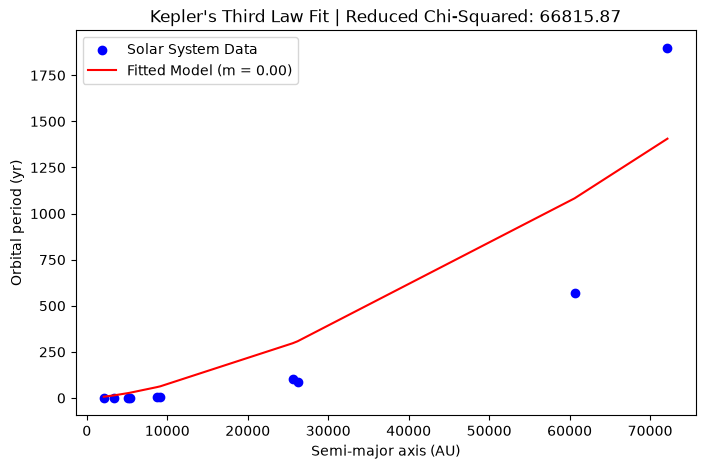

In [19]:
def keplers_third_law(a, m):
    return m * a ** 1.5

popt, pcov = curve_fit(keplers_third_law, semi_major_axis, orbital_period)

m_fit = popt[0]

print(f"Fit: T = {m_fit:.2f} * a^1.5")

residuals = orbital_period - keplers_third_law(semi_major_axis, m_fit)
chi2 = np.sum(residuals**2)
dof = len(semi_major_axis) - len(popt)
chi2_reduced = chi2 / dof

a_sorted = np.sort(semi_major_axis)

plt.figure(figsize=(8, 5))
plt.scatter(semi_major_axis, orbital_period, color="blue", label="Solar System Data")
plt.plot(a_sorted, keplers_third_law(a_sorted, m_fit), color="red", label=f"Fitted Model (m = {m_fit:.2f})")

plt.title(f"Kepler's Third Law Fit | Reduced Chi-Squared: {chi2_reduced:.2f}")
plt.xlabel("Semi-major axis (AU)")      # Match your CSV units
plt.ylabel("Orbital period (yr)")       # Match your CSV units
plt.legend()
plt.show()

In [ ]:
# 17 & 18. Save as kepler.csv inside your homework9/ folder
df.to_csv("kepler.csv")